# Student Academic Outcome Prediction (Gupio AI/ML Assignment - Option 1)

**Goal:** predict whether a student will end as **Dropout**, **Enrolled** or **Graduate**, using only information available **at enrollment**.

**How to use this notebook:** open it in VS Code, pick a Python kernel (the one where you ran `pip install -r requirements.txt`) and choose **Run All**. All the heavy lifting lives in the readable files in `src/`; this notebook calls them step by step and explains each result.

**The three rules that keep this honest**
1. The 12 semester-performance columns are **never used** (they are not known at enrollment = leakage).
2. The **test set is split off first** and not used for choosing or tuning anything.
3. Every learned preprocessing step (median, scaling, one-hot categories) lives inside a scikit-learn **Pipeline**, so it is learned from training data only.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Find the project root (the folder that contains "src") so imports work no matter
# where VS Code starts the notebook from.
ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import config, data_loader, eda, evaluate, interpret, predict, train
from src.models import get_models
from src.preprocessing import (build_preprocessor, make_train_test_split,
                               split_features_target)
from src.sensitivity import run_sensitivity

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
print("Project root:", ROOT.name)
print("Random seed :", config.RANDOM_SEED)

Project root: student-outcome-prediction
Random seed : 42


## 1. Load and inspect the data

The file is **semicolon-delimited**, so `data_loader.load_data()` reads it with `sep=";"`.

In [2]:
df = data_loader.load_data()
data_loader.check_columns(df)          # stops with a clear message if columns differ from the UCI dataset
info = data_loader.inspect_dataset(df)

Rows: 4424   Columns: 37
Missing values (total): 0
Duplicate rows: 0
Data types: {'int64': 29, 'float64': 7, 'str': 1}
Target classes (count): {'Graduate': 2209, 'Dropout': 1421, 'Enrolled': 794}
Target classes (%):     {'Graduate': 49.93, 'Dropout': 32.12, 'Enrolled': 17.95}


In [3]:
df.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,...,Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,...,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,...,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,...,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,...,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,...,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [4]:
# One row per column: its data type and the role it plays in this project
overview = data_loader.column_overview(df)
overview

,dtype,role,n_unique,n_missing
Marital status,int64,categorical (integer code),6,0
Application mode,int64,categorical (integer code),18,0
Application order,int64,numeric,8,0
Course,int64,categorical (integer code),17,0
Daytime/evening attendance,int64,binary (0/1),2,0
Previous qualification,int64,categorical (integer code),17,0
Previous qualification (grade),float64,numeric,101,0
Nacionality,int64,categorical (integer code),21,0
Mother's qualification,int64,categorical (integer code),29,0
Father's qualification,int64,categorical (integer code),34,0


**What this shows**
- **4,424 students x 37 columns**; **no missing values** and **no duplicate rows** (matches the UCI description).
- Data types: 29 integer columns, 7 decimal columns and 1 text column (`Target`).
- **Numerical variables (7):** the grades, age, application order and the three macro-economic indicators.
- **Binary 0/1 variables (8):** e.g. `Debtor`, `Scholarship holder`, `Gender`.
- **Encoded-categorical variables (9):** integer **codes** that stand for a category (e.g. `Course`, `Marital status`, parents' occupation). The size of a code means nothing, so we **one-hot encode** them instead of treating them as numbers.
- The 12 `Curricular units ...` columns are marked **PROHIBITED** and are excluded from the model.

In [5]:
print("Numeric ranges (min / median / max):")
display(data_loader.data_quality_notes(df))
print("Categorical-code columns: how many distinct codes, and how many are rare?")
display(data_loader.rare_category_table(df))

Numeric ranges (min / median / max):


,min,median,max
Application order,0.00,1.00,9.00
Previous qualification (grade),95.00,133.10,190.00
Admission grade,95.00,126.10,190.00
Age at enrollment,17.00,20.00,70.00
Unemployment rate,7.60,11.10,16.20
Inflation rate,-0.80,1.40,3.70
GDP,-4.06,0.32,3.51


Categorical-code columns: how many distinct codes, and how many are rare?


,n_codes,codes_with_<10_students,largest_code_share_%
column,,,
Marital status,6,2,88.6
Application mode,18,4,38.6
Course,17,0,17.3
Previous qualification,17,7,84.0
Nacionality,21,16,97.5
Mother's qualification,29,19,24.2
Father's qualification,34,22,27.3
Mother's occupation,32,18,35.6
Father's occupation,46,32,22.8


**Data-quality observations**
- **Rare categories:** many code columns have lots of codes with very few students (e.g. 32 of the 46 father's-occupation codes have fewer than 10 students; 16 of 21 nationality codes). A model can easily memorise such tiny groups, so the encoder is set to `handle_unknown="ignore"` and the models must be judged on unseen data.
- **Heavy imbalance inside columns:** 97.5% of students share one nationality code and 88.6% one marital-status code.
- **Age at enrollment** runs from 17 to 70 with a median of 20 - a long tail of mature students. These are real values, so they are kept (no rows are removed or altered).
- **Grades** (previous qualification and admission grade) are on a 95-190 scale.
- **Macro-economic columns** (unemployment, inflation, GDP) take only **9-10 distinct values** each, i.e. they are the same for every student who enrolled in the same period. They behave like a *cohort label*, not a personal characteristic.
- **Possible timing issue:** `Debtor` and `Tuition fees up to date` are allowed by the assignment, but fee status may be recorded *after* enrollment. We keep them in the primary model (as instructed) and test the impact in Section 10.
- The column name `Nacionality` is misspelled in the original UCI data; we keep it unchanged.

## 2. Target distribution

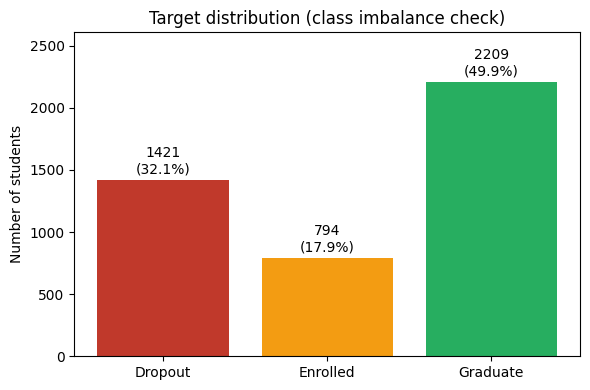

In [6]:
_ = eda.plot_target_distribution(df[config.TARGET])

**Class imbalance:** Graduate 2,209 (49.9%), Dropout 1,421 (32.1%), Enrolled 794 (17.9%).
A useless model that always says "Graduate" would already be right about 50% of the time - this is why **accuracy alone is misleading** and why we focus on **Macro F1** (the plain average of the three per-class F1 scores, so the small *Enrolled* class counts as much as *Graduate*).

## 3. Separate target from predictors, then split **before** looking at relationships

`split_features_target` keeps only the 24 permitted enrollment-time columns in `X` and puts `Target` in `y`.
The split is **80% train / 20% test**, **stratified** (each class keeps its proportion) with a fixed seed.
We do the feature-vs-target EDA on the **training data only**, so nothing seen in the test set can influence our choices.

In [7]:
X, y = split_features_target(df)
X_train, X_test, y_train, y_test = make_train_test_split(X, y)

print("Predictors:", X.shape[1], "columns (12 semester-performance columns excluded)")
print(f"Train: {len(X_train)} students | Test: {len(X_test)} students")
print("Train class %:", (y_train.value_counts(normalize=True) * 100).round(1).to_dict())
print("Test  class %:", (y_test.value_counts(normalize=True) * 100).round(1).to_dict())

train_df = X_train.assign(**{config.TARGET: y_train})   # training data + target, for EDA only

Predictors: 24 columns (12 semester-performance columns excluded)
Train: 3539 students | Test: 885 students
Train class %: {'Graduate': 49.9, 'Dropout': 32.1, 'Enrolled': 17.9}
Test  class %: {'Graduate': 49.9, 'Dropout': 32.1, 'Enrolled': 18.0}


## 4. Exploratory analysis: permitted predictors vs outcome (training data)
### 4a. Numeric predictors

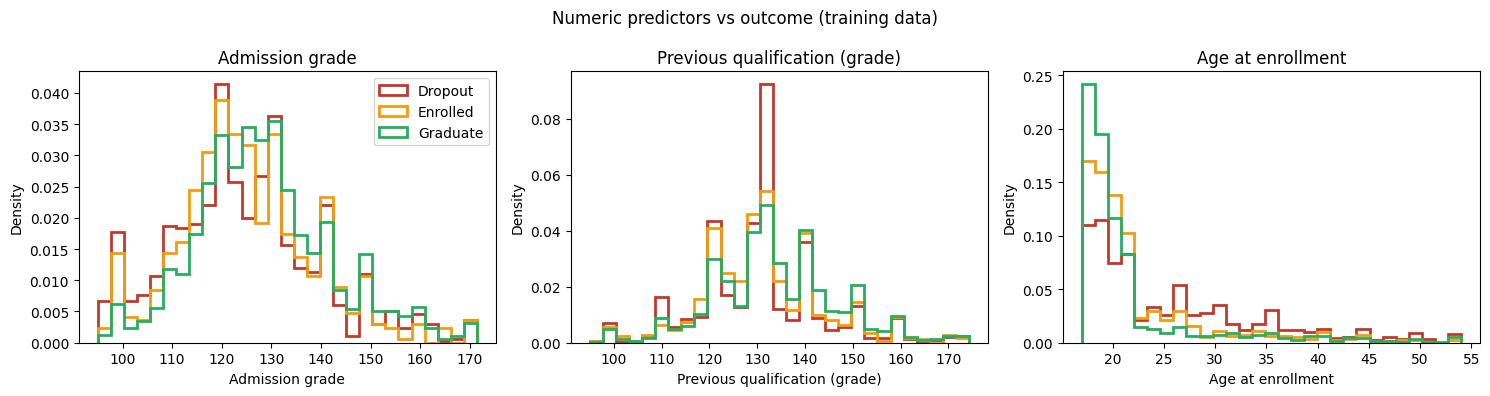

In [8]:
_ = eda.plot_numeric_by_target(train_df)

In [9]:
train_df.groupby(config.TARGET)[['Admission grade', 'Previous qualification (grade)', 'Age at enrollment']].median()

,Admission grade,Previous qualification (grade),Age at enrollment
Target,,,
Dropout,123.3,133.1,23.0
Enrolled,123.9,131.0,20.0
Graduate,127.3,133.1,19.0


Graduates have a slightly higher median admission grade (127.3) than Dropouts (123.3) and Enrolled (123.9) - a **small** difference. Age shows a much clearer pattern (next chart).

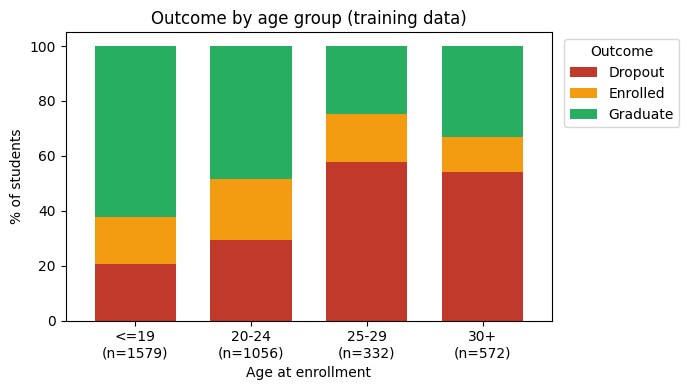

In [10]:
_ = eda.plot_age_group_outcomes(train_df)

**Age matters:** dropout is **20.7%** for students aged 19 or younger and **29.2%** for 20-24, but **57.8%** for 25-29 and **54.2%** for 30+.

### 4b. Binary (0/1) predictors

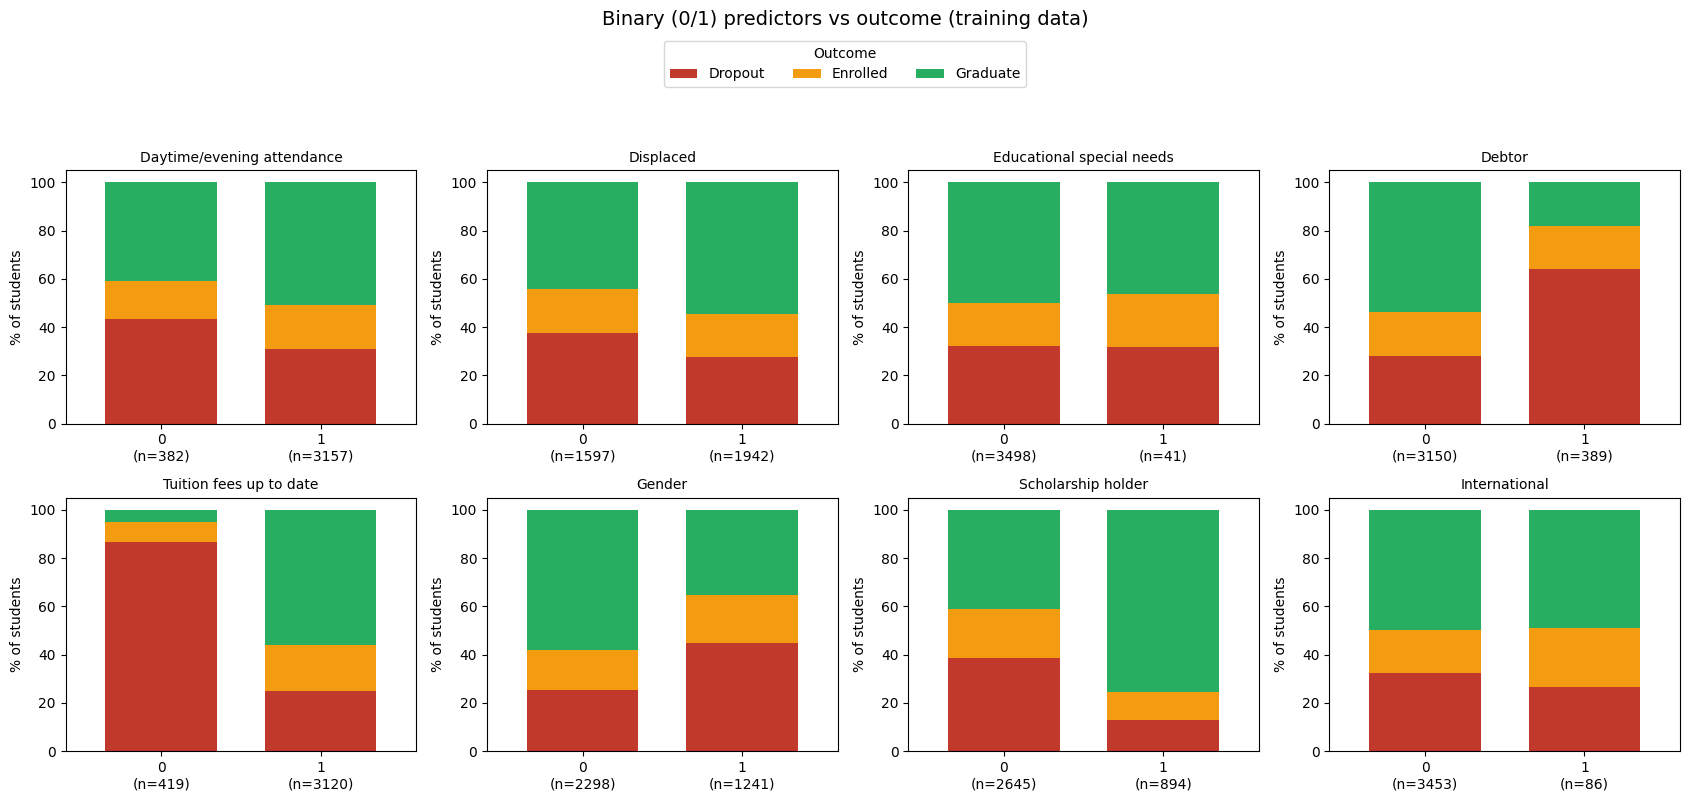

In [11]:
_ = eda.plot_binary_vs_target(train_df)

In [12]:
table = eda.binary_outcome_table(train_df)
table.pivot(index="feature", columns="value", values="dropout_%").rename(columns={0: "dropout % when 0", 1: "dropout % when 1"})

value,dropout % when 0,dropout % when 1
feature,,
Daytime/evening attendance,43.5,30.8
Debtor,28.2,64.0
Displaced,37.8,27.5
Educational special needs,32.1,31.7
Gender,25.3,44.8
International,32.3,26.7
Scholarship holder,38.6,12.9
Tuition fees up to date,86.9,24.8


**Strongest patterns (training data):**
- `Tuition fees up to date`: dropout **86.9%** when 0 vs **24.8%** when 1.
- `Debtor`: **64.0%** dropout for debtors vs **28.2%** for non-debtors.
- `Scholarship holder`: **12.9%** vs **38.6%** for non-holders.
- `Gender` (coded 0/1): dropout **44.8%** when 1 vs **25.3%** when 0.
- `Daytime/evening attendance` = 0: **43.5%** dropout vs **30.8%** when 1; `Displaced` = 1: **27.5%** vs **37.8%** when 0.
- `Educational special needs` (only 41 training students) and `International` (86) show little difference or too few students to say much.

These are *associations* in this dataset; they do not tell us why students drop out.

### 4c. Categorical (code) predictors

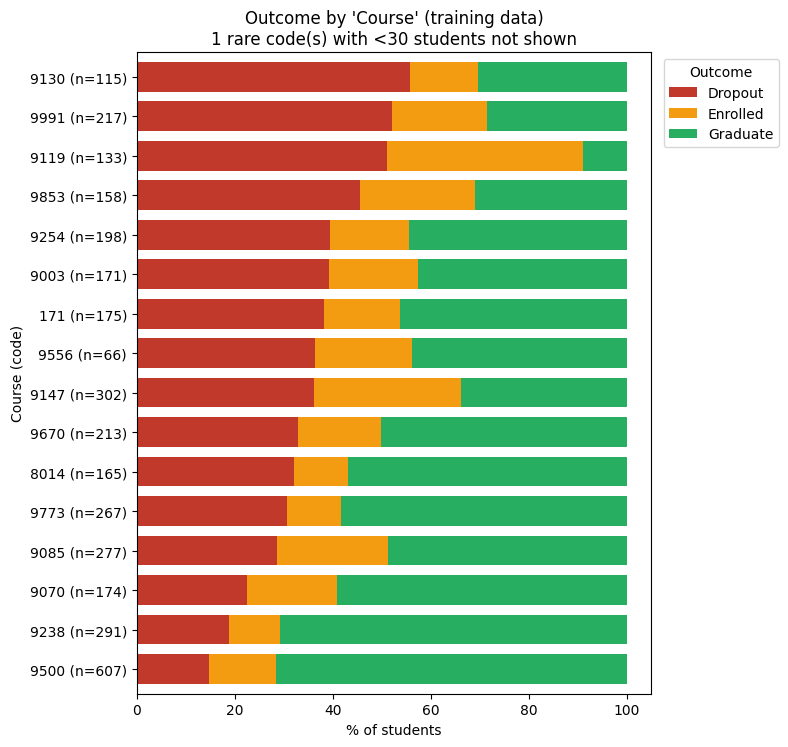

In [13]:
_ = eda.plot_categorical_vs_target(train_df, 'Course')

**Course** is strongly related to the outcome: among courses with at least 30 training students, dropout ranges from **14.8%** (code 9500, n=607) to **55.7%** (code 9130, n=115).

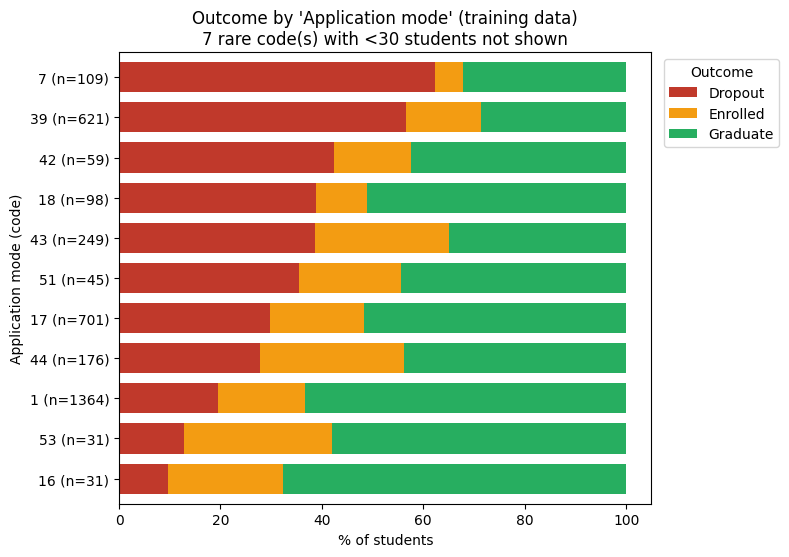

In [14]:
_ = eda.plot_categorical_vs_target(train_df, 'Application mode')

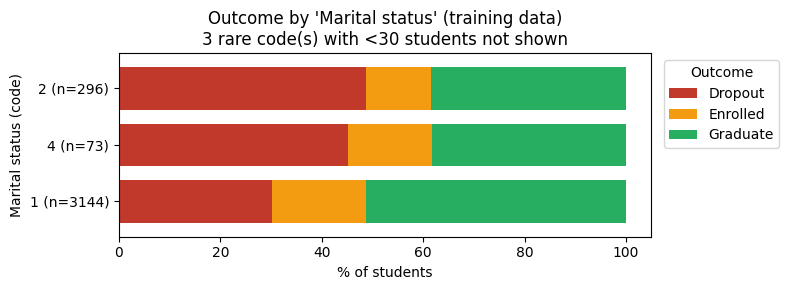

In [15]:
_ = eda.plot_categorical_vs_target(train_df, 'Marital status')

### 4d. Macro-economic context and correlations

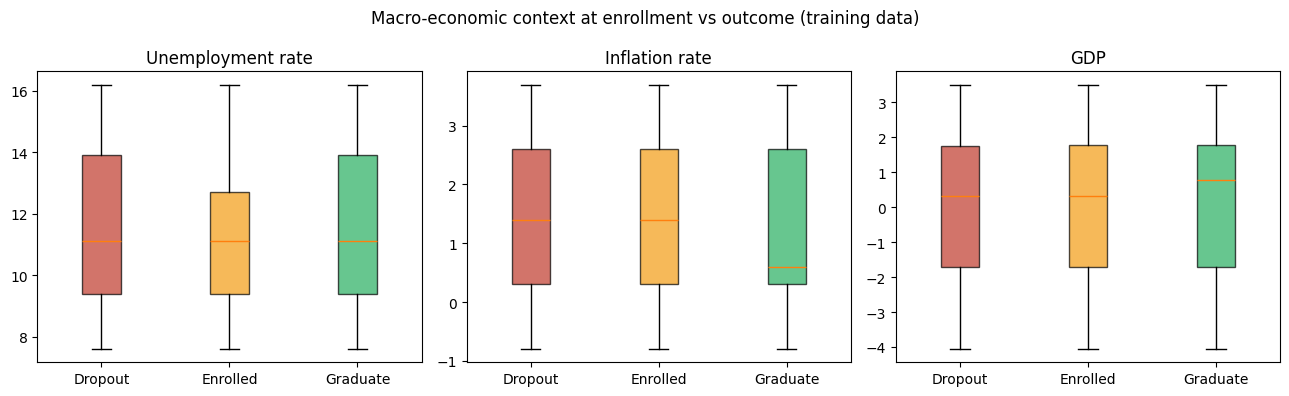

In [16]:
_ = eda.plot_macro_economic_by_target(train_df)

The three outcome groups look very similar on unemployment, inflation and GDP (the median unemployment rate is 11.1 for all three), so these columns carry little visible signal on their own.

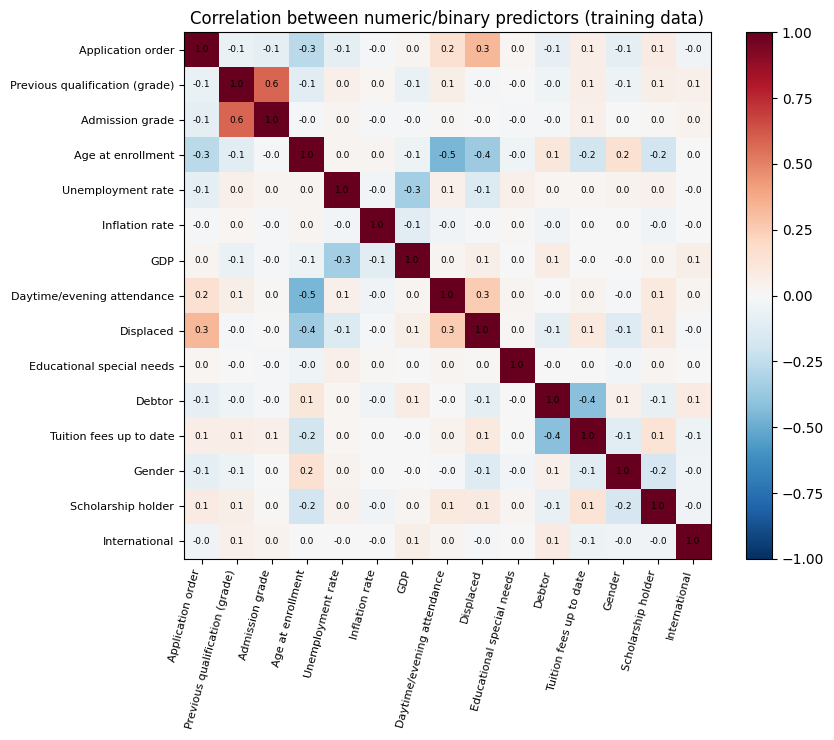

In [17]:
_ = eda.plot_correlation_heatmap(train_df)

Most predictors are only weakly correlated with each other. The notable exceptions: `Admission grade` vs `Previous qualification (grade)` (about 0.6), `Age at enrollment` vs `Daytime/evening attendance` (about -0.5) and `Debtor` vs `Tuition fees up to date` (about -0.4). Tree models cope fine with correlated inputs; for Logistic Regression it only slightly affects coefficient interpretation.

## 5. Leakage-safe preprocessing

| Column type | Steps | Why |
|---|---|---|
| Numeric (7) | median imputer -> `StandardScaler` | scaling helps Logistic Regression; imputer is a safety net (there are no missing values) |
| Binary 0/1 (8) | most-frequent imputer, otherwise unchanged | already numeric |
| Categorical codes (9) | most-frequent imputer -> `OneHotEncoder(handle_unknown="ignore")` | codes have no order; unseen codes must not crash prediction |

All of this sits **inside** the Pipeline, so `.fit()` learns the medians, means and category lists from **training data only**. The test set only ever goes through `.transform()` / `.predict()`.

In [18]:
preprocessor = build_preprocessor()
preprocessor.fit(X_train)                       # learns from TRAINING data only

print("Training matrix:", X_train.shape, "->", preprocessor.transform(X_train).shape)
print("Test matrix    :", X_test.shape, "->", preprocessor.transform(X_test).shape)
print("(24 original columns become", preprocessor.transform(X_train).shape[1], "numeric columns after one-hot encoding)")

Training matrix: (3539, 24) -> (3539, 224)
Test matrix    : (885, 24) -> (885, 224)
(24 original columns become 224 numeric columns after one-hot encoding)


## 6. Compare models with cross-validation (training data only)

We compare five candidates. All use the same preprocessing; the three imbalance-aware models use `class_weight="balanced"` (errors on the small *Enrolled* class cost more **during training**; no rows are copied or removed).

| Model | Why it is here |
|---|---|
| Dummy (most frequent) | the floor any real model must beat |
| Logistic Regression (no weights) | simple baseline |
| Logistic Regression (balanced) | same baseline + class weights, to measure the effect of imbalance handling |
| Random Forest (balanced) | tree ensemble |
| Gradient Boosting (balanced) | boosted trees |

**Selection rule (decided before looking at the test set):** the model with the highest mean **Macro F1** in 5-fold stratified cross-validation on the training set.

In [19]:
models = get_models()
cv_results = train.cross_validate_models(models, X_train, y_train)
best_name = train.select_best_model(cv_results)
print("\nSelected model (highest CV Macro F1):", best_name)
cv_results.round(4)

  CV  Dummy (most frequent)              macro-F1 = 0.2220 (+/- 0.0002)   [0s]
  CV  Logistic Regression (no weights)   macro-F1 = 0.5517 (+/- 0.0151)   [1s]
  CV  Logistic Regression (balanced)     macro-F1 = 0.5674 (+/- 0.0159)   [1s]
  CV  Random Forest (balanced)           macro-F1 = 0.5726 (+/- 0.0227)   [6s]
  CV  Gradient Boosting (balanced)       macro-F1 = 0.5820 (+/- 0.0087)   [11s]

Selected model (highest CV Macro F1): Gradient Boosting (balanced)


,cv_macro_f1_mean,cv_macro_f1_std,cv_accuracy_mean,cv_balanced_accuracy_mean
model,,,,
Dummy (most frequent),0.2220,0.0002,0.4993,0.3333
Logistic Regression (no weights),0.5517,0.0151,0.6496,0.5488
Logistic Regression (balanced),0.5674,0.0159,0.6027,0.5770
Random Forest (balanced),0.5726,0.0227,0.6346,0.5716
Gradient Boosting (balanced),0.5820,0.0087,0.6197,0.5896


## 7. Fit on the training set and evaluate on the unseen test set

Each model is fitted on the training data and then scored **once** on the 885 test students.

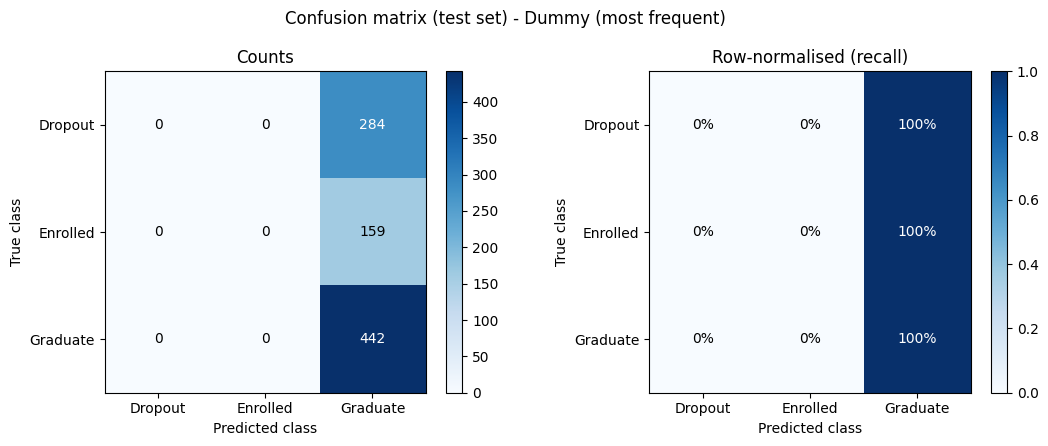

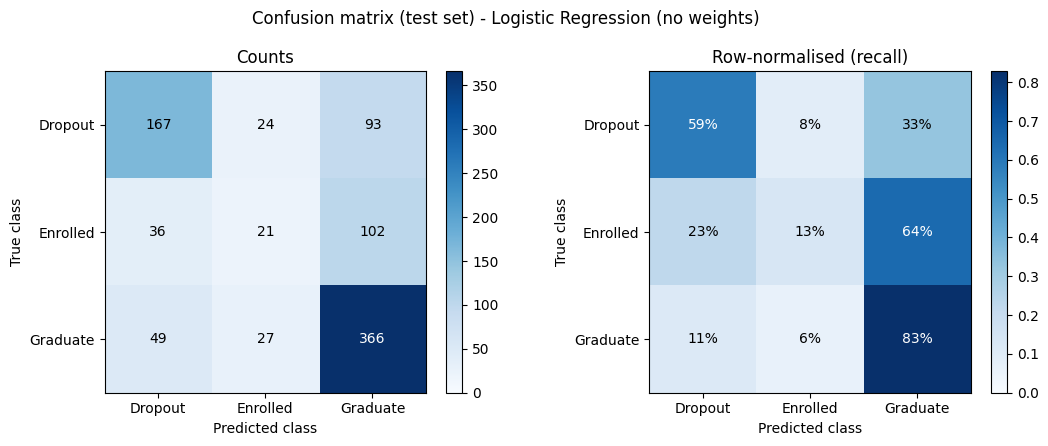

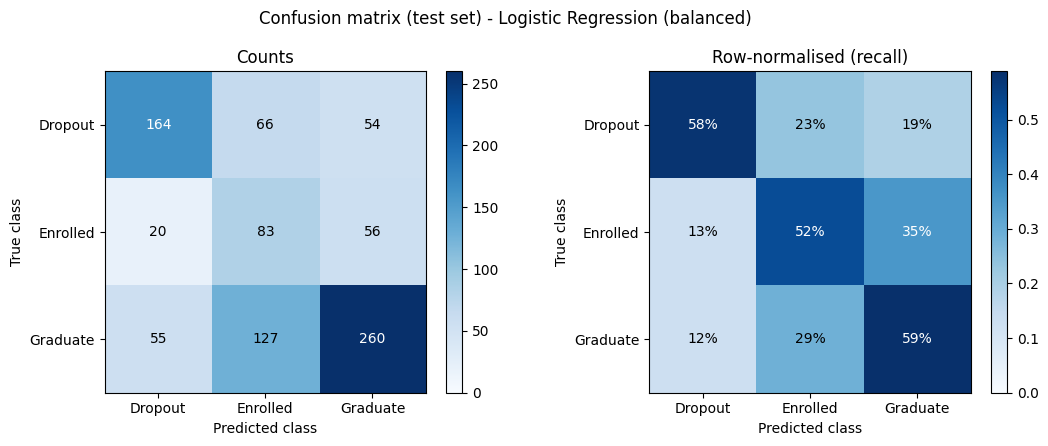

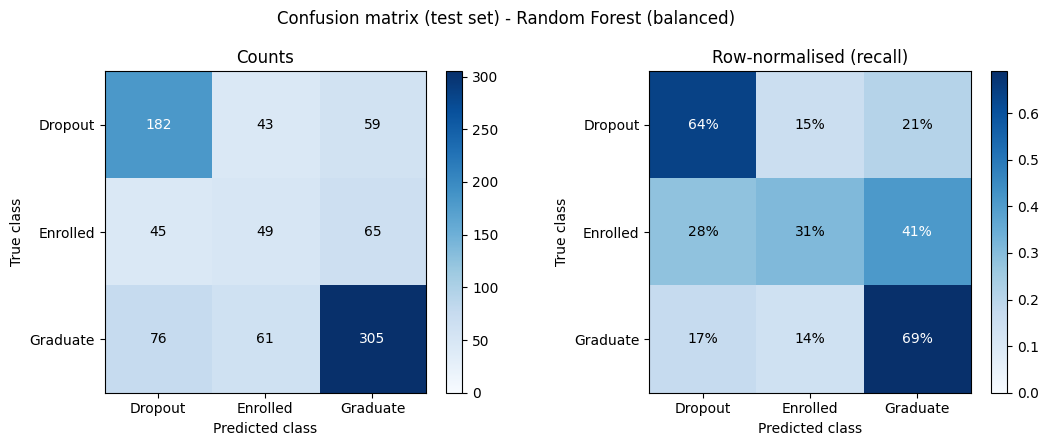

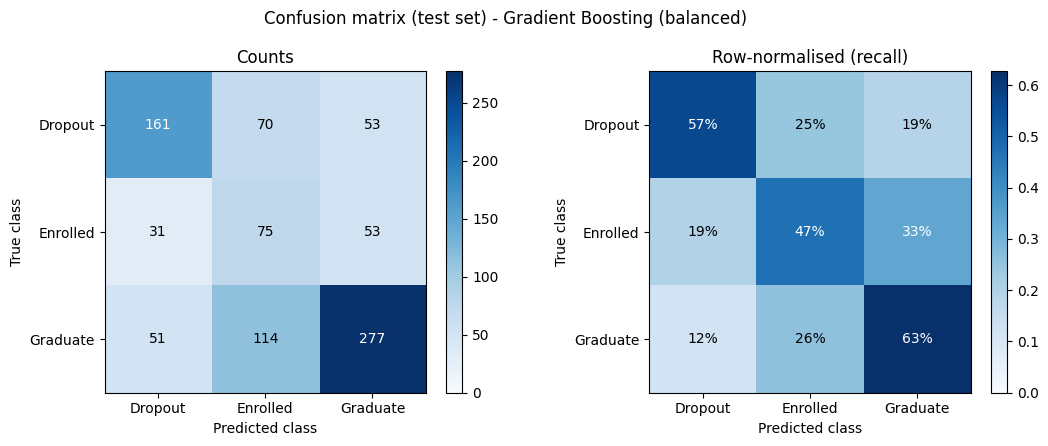

,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
model,,,,,,
Dummy (most frequent),0.4994,0.3333,0.1665,0.3333,0.2221,0.3327
Logistic Regression (no weights),0.6260,0.5161,0.5356,0.5161,0.5116,0.5971
Logistic Regression (balanced),0.5729,0.5626,0.5632,0.5626,0.5497,0.5897
Random Forest (balanced),0.6056,0.5464,0.5440,0.5464,0.5448,0.6052
Gradient Boosting (balanced),0.5797,0.5551,0.5585,0.5551,0.5471,0.5959


In [20]:
fitted, test_table, per_class, predictions = train.fit_and_evaluate(
    models, X_train, y_train, X_test, y_test)
test_table.round(4)

### Per-class Precision / Recall / F1 (test set)

In [21]:
for name in models:
    print(f"--- {name} ---")
    display(per_class[name].round(3))

--- Dummy (most frequent) ---


,precision,recall,f1-score,support
Dropout,0.000,0.0,0.000,284
Enrolled,0.000,0.0,0.000,159
Graduate,0.499,1.0,0.666,442


--- Logistic Regression (no weights) ---


,precision,recall,f1-score,support
Dropout,0.663,0.588,0.623,284
Enrolled,0.292,0.132,0.182,159
Graduate,0.652,0.828,0.730,442


--- Logistic Regression (balanced) ---


,precision,recall,f1-score,support
Dropout,0.686,0.577,0.627,284
Enrolled,0.301,0.522,0.382,159
Graduate,0.703,0.588,0.640,442


--- Random Forest (balanced) ---


,precision,recall,f1-score,support
Dropout,0.601,0.641,0.620,284
Enrolled,0.320,0.308,0.314,159
Graduate,0.711,0.690,0.700,442


--- Gradient Boosting (balanced) ---


,precision,recall,f1-score,support
Dropout,0.663,0.567,0.611,284
Enrolled,0.290,0.472,0.359,159
Graduate,0.723,0.627,0.672,442


### Confusion matrices (test set; rows = true class, columns = predicted class)

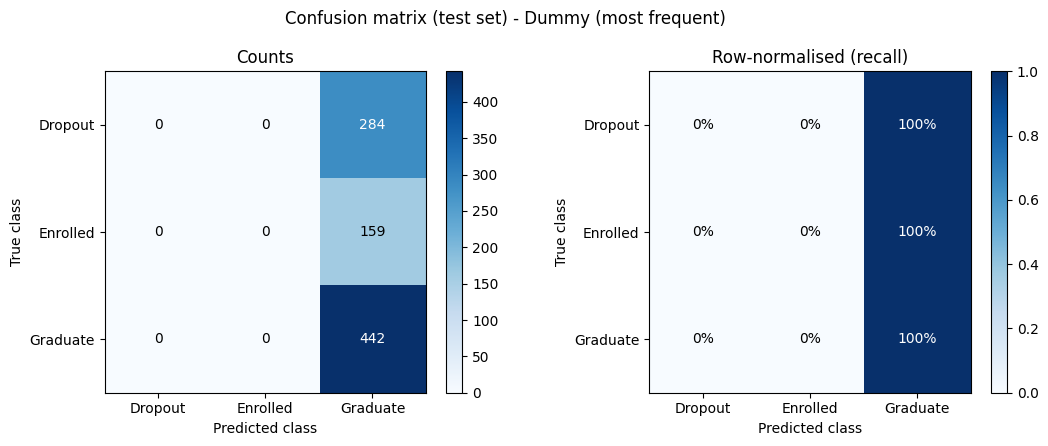

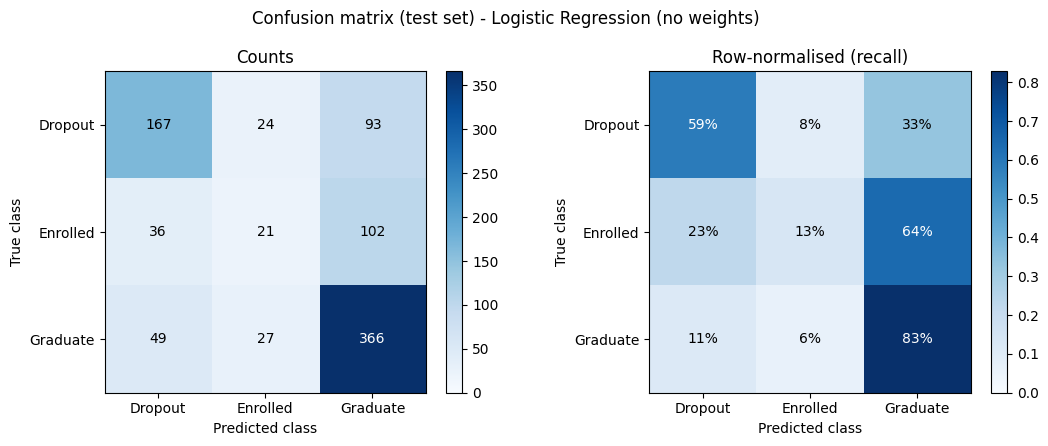

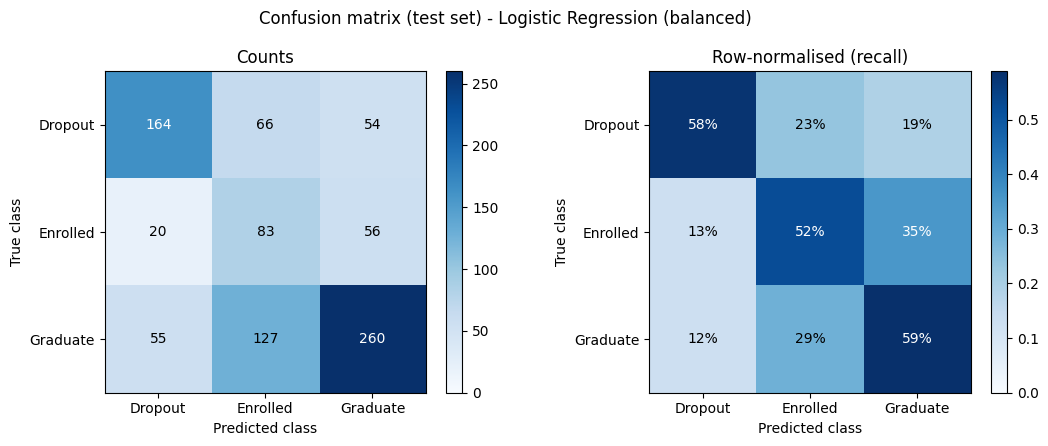

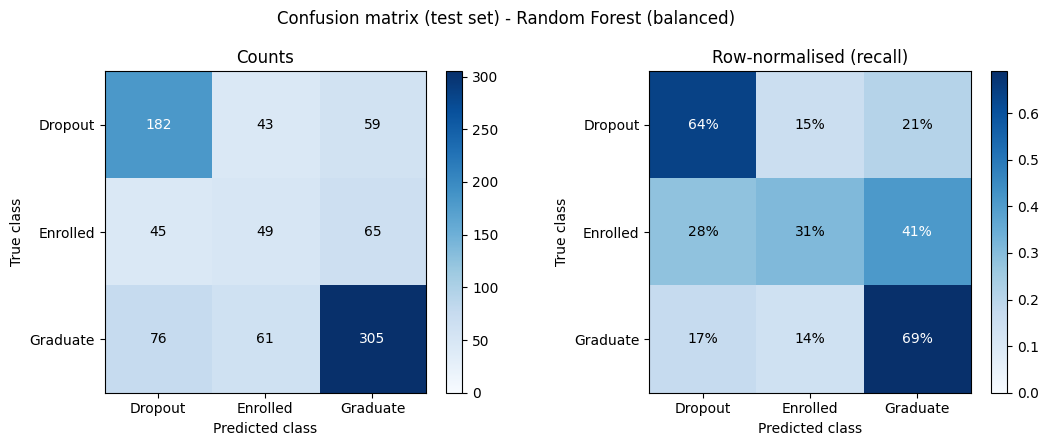

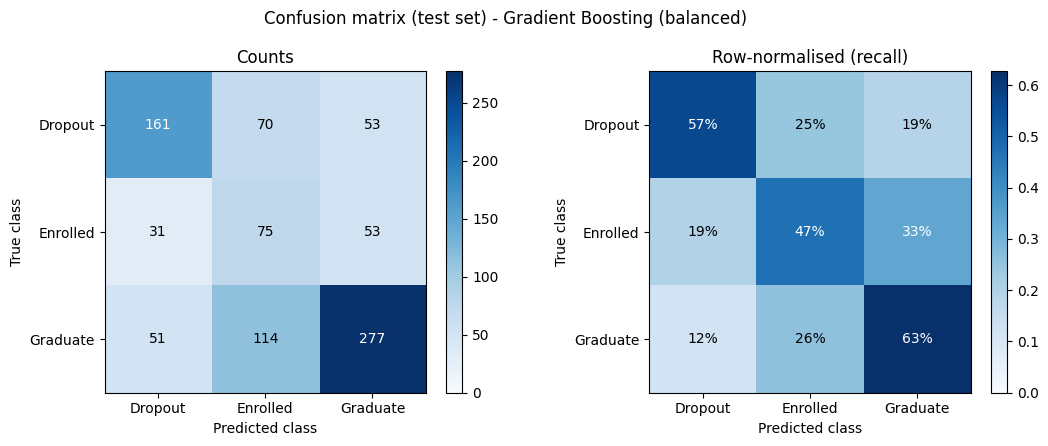

In [22]:
for name in models:
    evaluate.plot_confusion_matrix(y_test, predictions[name], f"Confusion matrix (test set) - {name}")
    plt.show()

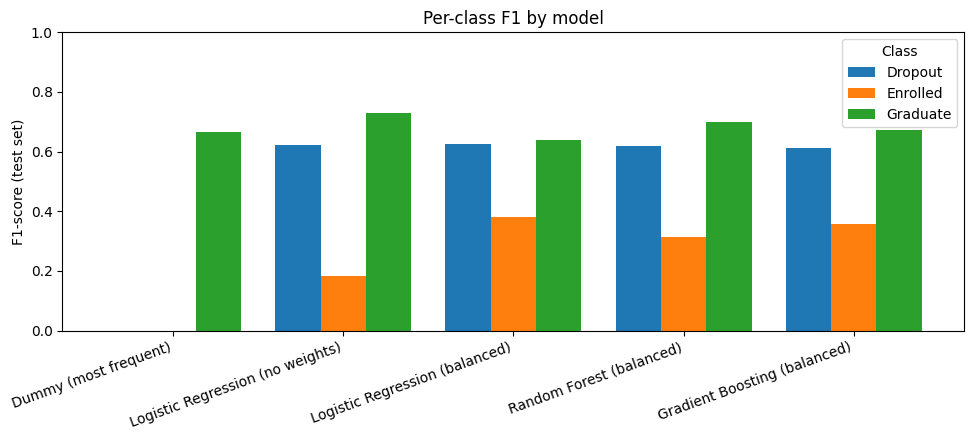

In [23]:
_ = evaluate.plot_per_class_f1(per_class)

## 8. Class imbalance, model comparison and final choice

**Effect of class imbalance (read this off the tables above).**
- *Enrolled* is the hard class for every model. Plain Logistic Regression (no weights) finds only **13.2%** of Enrolled students (F1 0.18) while reaching the highest accuracy (0.626) - it wins on accuracy mostly by favouring the big *Graduate* class (recall 82.8%).
- Adding `class_weight="balanced"` lifts Enrolled recall to **52.2%** (F1 0.38) but costs accuracy (0.573). Macro F1 improves from **0.512 to 0.550**. That trade-off is exactly what accuracy alone hides.
- *Dropout* is handled reasonably (F1 about 0.61-0.63 in every real model); *Graduate* is handled best (F1 0.64-0.73); *Enrolled* is poorest (F1 0.18-0.38, precision only about 0.29-0.32): many students predicted "Enrolled" are not.

**Final model: Gradient Boosting (balanced).**
- It has the **highest cross-validated Macro F1 (0.582)** and the **smallest fold-to-fold spread (+/- 0.009)**, plus the best CV balanced accuracy (0.590).
- On the untouched test set it scores **Macro F1 0.547**, accuracy 0.580; per-class F1: Dropout 0.611, Enrolled 0.359, Graduate 0.672. It catches **47.2%** of Enrolled students and 56.7% of Dropouts.

**Honest caveat.** On the test set the three balanced models are essentially tied on Macro F1 (Logistic Regression 0.550, Gradient Boosting 0.547, Random Forest 0.545). With only 885 test students, differences of 0.005 are within noise, so we **do not** switch models after seeing test scores - doing so would turn the test set into a selection tool. The choice stays with the rule fixed in advance (best CV Macro F1). All three balanced models are reasonable; Logistic Regression is the simplest to explain.

The dummy baseline's Macro F1 is only 0.222, so every real model has learned something, but **overall performance is moderate** (Macro F1 about 0.55): enrollment-time information alone cannot predict outcomes very accurately.

In [24]:
summary = train.save_results(cv_results, test_table, per_class, y_test, predictions, best_name)
train.save_model(fitted[best_name], best_name, X_train)
print("Saved models/best_model.joblib and all result tables in outputs/")
summary

Saved models/best_model.joblib and all result tables in outputs/


{'selection_rule': 'highest mean 5-fold CV Macro F1 on the training set', 'selected_model': 'Gradient Boosting (balanced)', 'cv_macro_f1_mean': 0.582, 'test_metrics': {'accuracy': 0.5797, 'balanced_accuracy': 0.5551, 'macro_precision': 0.5585, 'macro_recall': 0.5551, 'macro_f1': 0.5471, 'weighted_f1': 0.5959}}

## 9. Interpretation: which features does the final model use?

We use **permutation importance**: shuffle one column of the test data and see how much Macro F1 drops. It is measured on the **original columns** (e.g. `Course`, not `Course_9500`).

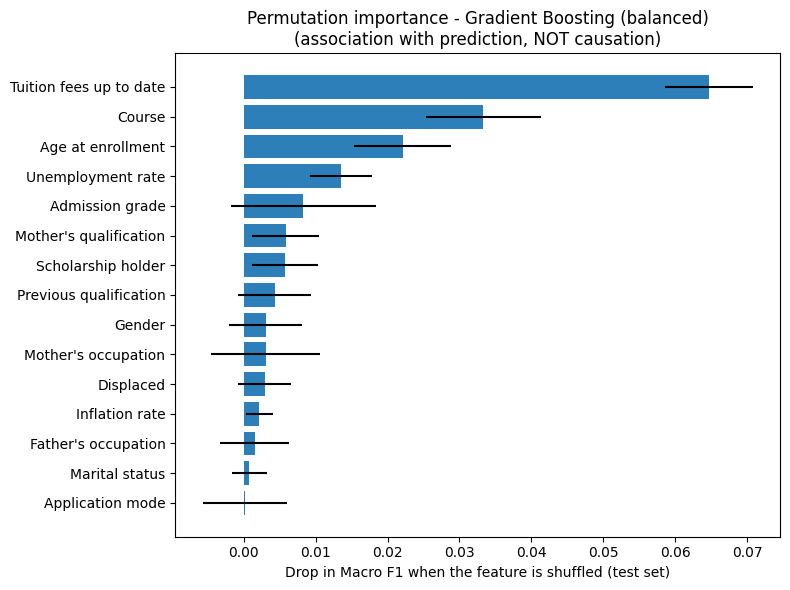

,feature,importance_macro_f1_drop,std
0,Tuition fees up to date,0.0647,0.0061
1,Course,0.0333,0.0080
2,Age at enrollment,0.0221,0.0068
3,Unemployment rate,0.0135,0.0043
4,Admission grade,0.0083,0.0101
5,Mother's qualification,0.0058,0.0047
6,Scholarship holder,0.0057,0.0046
7,Previous qualification,0.0043,0.0051
8,Gender,0.0030,0.0051
9,Mother's occupation,0.0030,0.0076


In [25]:
importance = interpret.compute_permutation_importance(fitted[best_name], X_test, y_test)
importance.round(4).to_csv(config.OUTPUT_DIR / "feature_importance.csv", index=False)
_ = interpret.plot_importance(importance, best_name)
importance.head(10).round(4)

**Reading the chart**
- `Tuition fees up to date` is by far the most important (Macro F1 drops by about 0.065 when it is shuffled), followed by `Course` (0.033), `Age at enrollment` (0.022) and `Unemployment rate` (0.014). This matches the EDA: fee status, course and age showed the largest differences in outcome.
- `Admission grade`, `Mother's qualification` and `Scholarship holder` contribute a little; most other columns add almost nothing. Several bars have error bars that cross zero, so their ranking is not reliable.
- `Unemployment rate` takes only 10 distinct values, so it most likely lets the model recognise the **enrollment cohort/period** rather than describing an individual student.

> **Importance is not causation.** A high-importance feature is one the model *uses*; it does not show that changing that feature would change a student's outcome. For example, unpaid fees may be a *symptom* of a student already disengaging.

## 10. Sample predictions with the saved model

`predict.run_demo()` **loads `models/best_model.joblib` from disk** and predicts for six unseen test students (two per true class) plus two made-up students. The saved object is the whole pipeline, so new data gets **exactly** the same preprocessing as in training.

In [26]:
sample_predictions = predict.run_demo()
sample_predictions

,actual_outcome,predicted_outcome,P(Dropout),P(Enrolled),P(Graduate),correct
4055,Dropout,Dropout,0.553,0.306,0.141,yes
3003,Dropout,Graduate,0.108,0.271,0.621,NO
3653,Enrolled,Enrolled,0.170,0.497,0.334,yes
186,Enrolled,Dropout,0.821,0.140,0.039,NO
2271,Graduate,Graduate,0.174,0.232,0.594,yes
168,Graduate,Dropout,0.543,0.184,0.272,NO
Hypothetical A (typical),(unknown - made up),Graduate,0.101,0.383,0.517,n/a
"Hypothetical B (debt, fees overdue, age 30)",(unknown - made up),Dropout,0.963,0.032,0.005,n/a


Three of the six real test students are classified correctly. The three misses are a Dropout predicted as Graduate, an Enrolled student predicted as Dropout (probability 0.82) and a Graduate predicted as Dropout. Six students are only an illustration, **not** a performance estimate (the test-set metrics in Section 7 are). The two hypothetical students only show that the model accepts new records - they are **not** evidence that changing debt or age would change an outcome.

## 11. Sensitivity check: what if the two fee columns are not known at enrollment?

Re-running the chosen model **without** `Debtor` and `Tuition fees up to date` (22 features):

In [27]:
sens_table, sens_per_class = run_sensitivity(best_name, X_train, y_train, X_test, y_test, cv_results, test_table)
display(sens_table)
sens_per_class.round(3)

  CV  Gradient Boosting (balanced)       macro-F1 = 0.5291 (+/- 0.0132)   [11s]


,cv_macro_f1,test_macro_f1,test_accuracy
setting,,,
Primary (all 24 features),0.5820,0.5471,0.5797
"Without Debtor, Tuition fees up to date (22 features)",0.5291,0.5333,0.5672


,precision,recall,f1-score,support
Dropout,0.587,0.546,0.566,284
Enrolled,0.308,0.465,0.371,159
Graduate,0.717,0.618,0.663,442


Cross-validated Macro F1 falls from **0.582 to 0.529** and test Macro F1 from **0.547 to 0.533**. So the fee columns help, but the model still beats the dummy baseline (0.222) without them. If fee status turns out to be recorded after enrollment, the realistic enrollment-only performance is closer to the lower figure.

## 12. Limitations

- **Prediction is not causation.** The model finds statistical patterns in past students; it cannot say *why* students drop out or what would change an outcome.
- **Moderate performance.** Test Macro F1 is about 0.55 and the *Enrolled* class is predicted poorly (F1 about 0.36, precision about 0.29). It should not be used to make decisions about individual students without human review.
- **Single split.** The test score comes from one 885-student test set, so it has noticeable uncertainty. Cross-validation spread (+/- 0.009 to +/- 0.023) shows the same.
- **Possible timing leakage** in `Debtor` / `Tuition fees up to date` (see Section 11).
- **Cohort proxy:** macro-economic columns identify enrollment periods, so the model may not transfer to other years or institutions.
- **Rare codes** (occupations, nationalities) are noisy; unseen codes are ignored at prediction time.
- **Single institution / dataset** (Portuguese higher-education data); fairness across groups (e.g. gender, nationality) has **not** been audited.
- **No hyperparameter tuning** was performed; models use sensible fixed settings.
- The numbers above depend on library versions; re-running with the same seed on the same versions gives identical results.